# **Titanic Survival Prediction**
data : https://github.com/cheetah0212/Machine_Learning_2025

## Step 1: Data Loading and Splitting (10%)
Load the Titanic dataset, then split it into three distinct sets with 'Survived' as the target variable: Training Set (80%), Testing Set (10%), and Validation Set (10%).

- Use `random_state=42` and **stratify** on 'Survived', so that all three sets keep the same survival ratio.
- Print the shape of each set and the proportion of survivors in each set.

In [1]:
import pandas as pd
url = "https://raw.githubusercontent.com/cheetah0212/Machine_Learning_2025/main/w10_data.csv"
df = pd.read_csv(url)
#print(df.head())

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
) 

for name, X_, y_ in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    print(name, "shape: ", X_.shape, "| survival rate:", round(y_.mean(), 4))
    


Train shape:  (712, 11) | survival rate: 0.3834
Validation shape:  (89, 11) | survival rate: 0.382
Test shape:  (90, 11) | survival rate: 0.3889


## Step 2: Feature Engineering (Optional) and Preprocessing Definition (20%)
This dataset has many features, define your best strategy for dropping / keeping / creating features. **This step can help increasing the final accuracy**.

- Create **at least two new features** from the existing columns (hint: combine related columns, or extract information hidden in a text column).
- Handle missing values. Any statistic you use (median, mode, ...) must be computed from the **training set only**, then applied to the validation and testing sets.
- Convert categorical features into numerical ones (e.g., one-hot encoding), and make sure all three sets end up with exactly the same columns.
- **Scale** the numerical features (neural networks are sensitive to the scale of the inputs). Fit the scaler on the training set only.
- Print the selected features and the shape of the final training, validation and testing feature matrices.

In [2]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Statistics computed from the TRAINING set only (no leakage into val/test)
age_median = X_train["Age"].median()
fare_median = X_train["Fare"].median()
embarked_mode = X_train["Embarked"].mode()[0]
common_titles = ["Mr", "Mrs", "Miss", "Master"]

def get_title(d):
    t = d["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
    return t.where(t.isin(common_titles), "Other")           # merge rare titles into "Other"

# median age of each title, from the training set only (a better guess than one overall median)
title_age_median = X_train.assign(Title=get_title(X_train)).groupby("Title")["Age"].median()

def preprocess(d):
    d = d.copy()
    # new features
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1                 # the passenger counts too
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["HasCabin"] = d["Cabin"].notna().astype(int)                # missing Cabin is informative
    d["Title"] = get_title(d)
    # missing values
    d["Age"] = d["Age"].fillna(d["Title"].map(title_age_median)).fillna(age_median)
    d["Fare"] = d["Fare"].fillna(fare_median)
    d["Embarked"] = d["Embarked"].fillna(embarked_mode)
    d["IsChild"] = (d["Age"] < 13).astype(int)
    d["FarePerPerson"] = d["Fare"] / d["FamilySize"]              # Fare is the whole family's ticket price
    d["LogFare"] = np.log1p(d["Fare"])                            # Fare is heavily right-skewed
    # drop columns that are not useful anymore
    return d.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

X_train_f, X_val_f, X_test_f = preprocess(X_train), preprocess(X_val), preprocess(X_test)

# one-hot encoding; val/test are aligned to the training columns so all sets match exactly
cat_cols = ["Sex", "Embarked", "Title"]
X_train_f = pd.get_dummies(X_train_f, columns=cat_cols, dtype=int)
X_val_f = pd.get_dummies(X_val_f, columns=cat_cols, dtype=int).reindex(columns=X_train_f.columns, fill_value=0)
X_test_f = pd.get_dummies(X_test_f, columns=cat_cols, dtype=int).reindex(columns=X_train_f.columns, fill_value=0)

# scaling: fit on the training set only
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_f)
X_val_s = scaler.transform(X_val_f)
X_test_s = scaler.transform(X_test_f)

print("Selected features:", list(X_train_f.columns))
print("Train:", X_train_s.shape, "| Validation:", X_val_s.shape, "| Test:", X_test_s.shape)

Selected features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'IsChild', 'FarePerPerson', 'LogFare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Other']
Train: (712, 21) | Validation: (89, 21) | Test: (90, 21)


## Step 3: Construct a Deep Neural Network Model (20%)
Build a DNN with Keras.

- Use **at least 3 hidden layers**, and the number of nodes should not be the same in every hidden layer.
- Choose the activation functions based on the lecture (hidden layers vs. the output layer of a binary classification task), and add a short comment explaining why you chose the activation function of each layer.

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def build_model(n_features):
    l2 = keras.regularizers.l2(1e-3)            # L2 penalty on weights, limits overfitting on this small dataset
    return keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(32, activation="relu", kernel_regularizer=l2),   # ReLU: cheap, avoids vanishing gradients in hidden layers
        layers.Dropout(0.2),                                          # dropout also reduces overfitting
        layers.Dense(16, activation="relu", kernel_regularizer=l2),   # ReLU again: non-linear, and simple to compute and train
        layers.Dropout(0.1),
        layers.Dense(8, activation="relu", kernel_regularizer=l2),    # ReLU again: same reason as the other hidden layers
        layers.Dense(1, activation="sigmoid"),  # sigmoid: outputs a probability in (0, 1) for binary classification
    ])

n_features = X_train_s.shape[1]


## Step 4: Model Compilation (15%)
Compile the constructed DNN model with appropriate settings for a binary classification task.

- Choose the optimizer (SGD, RMSProp or Adam) and **set its learning rate explicitly** (do not rely on the default value). Add a short comment explaining your choice.
- Choose a suitable loss function and metric.
- Display the model.summary() to verify the structure and parameter count.

In [4]:
keras.utils.set_random_seed(42)
model = build_model(n_features)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # Adam: adaptive step sizes, works well with little tuning
    loss="binary_crossentropy",                             # standard loss for a 0/1 target with a sigmoid output
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,377 (5.38 KB)

 Trainable params: 1,377 (5.38 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Model Training and Accuracy Output (35%)
Train the compiled model, employ optimization techniques, and evaluate its performance on the local validation and testing sets.

- Use mini-batch gradient descent: set `batch_size` between 8 and 256 and choose the number of epochs yourself.
- Monitor the training with the **validation set** (not the testing set), and use it to decide how many epochs to train.
- Plot the training loss and validation loss against the epochs, and describe in one or two sentences whether the model overfits.
- Compare **at least two settings** with the same architecture (e.g., Adam vs. RMSProp, or two different learning rates). Print their validation accuracy, and choose the final model by validation accuracy only.
- Do not use the testing set to select the model or tune any hyperparameter. Print the validation accuracy and the testing accuracy of your final model.

Measure your model's performance on the test set. Of the 35 points, **20 points** depend on the test accuracy you reach, and the other **15 points** are for completing the requirements above (validation set, loss curves with your comment, comparison of settings).

| Test accuracy | Score |
|---|---|
| < 65%, or not computed | 0 / 20 |
| ≥ 65% | 8 / 20 |
| ≥ 70% | 12 / 20 |
| ≥ 75% | 16 / 20 |
| ≥ 78% | 20 / 20 |

Print the test accuracy so that it is visible in your notebook.

Adam lr=0.001: epochs run = 77, validation accuracy = 0.8315, validation loss = 0.4028


Adam lr=0.0003: epochs run = 168, validation accuracy = 0.8315, validation loss = 0.4075


RMSprop lr=0.001: epochs run = 98, validation accuracy = 0.8427, validation loss = 0.4041


RMSprop lr=0.0003: epochs run = 167, validation accuracy = 0.8539, validation loss = 0.4076

Selected: RMSprop lr=0.0003


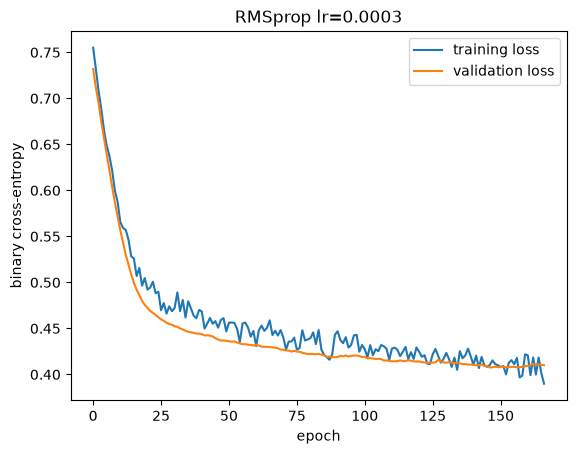

Lowest validation loss at epoch 147: train loss = 0.4102, val loss = 0.4076
Last epoch (167): train loss = 0.3899, val loss = 0.4100
Validation accuracy: 0.8539
Test accuracy: 0.7778


In [5]:
import matplotlib.pyplot as plt

def train(optimizer_name, lr, epochs=200, batch_size=32):
    keras.utils.set_random_seed(42)
    m = build_model(n_features)
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop}[optimizer_name](learning_rate=lr)
    m.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    # stop when validation loss stops improving, and keep the best weights -> this decides the number of epochs
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
    h = m.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
              epochs=epochs, batch_size=batch_size, callbacks=[stop], verbose=0)
    return m, h

settings = {
    "Adam lr=0.001": ("adam", 0.001),
    "Adam lr=0.0003": ("adam", 0.0003),
    "RMSprop lr=0.001": ("rmsprop", 0.001),
    "RMSprop lr=0.0003": ("rmsprop", 0.0003),
}
results = {}
for label, (opt_name, lr) in settings.items():
    m, h = train(opt_name, lr)
    val_loss, val_acc = m.evaluate(X_val_s, y_val, verbose=0)
    results[label] = (m, h, val_acc, val_loss)
    print(f"{label}: epochs run = {len(h.history['loss'])}, validation accuracy = {val_acc:.4f}, validation loss = {val_loss:.4f}")

# choose the final model by VALIDATION accuracy only; ties are broken by the lower validation loss
best_label = max(results, key=lambda k: (results[k][2], -results[k][3]))
best_model, best_hist, best_val_acc, _ = results[best_label]
print("\nSelected:", best_label)

# loss curves of the selected model
plt.plot(best_hist.history["loss"], label="training loss")
plt.plot(best_hist.history["val_loss"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.legend(); plt.title(best_label)
plt.show()

# numbers behind the overfitting comment
tr_loss, va_loss = best_hist.history["loss"], best_hist.history["val_loss"]
best_epoch = int(np.argmin(va_loss))
print(f"Lowest validation loss at epoch {best_epoch + 1}: train loss = {tr_loss[best_epoch]:.4f}, val loss = {va_loss[best_epoch]:.4f}")
print(f"Last epoch ({len(va_loss)}): train loss = {tr_loss[-1]:.4f}, val loss = {va_loss[-1]:.4f}")

# the testing set is used only once, for the final model
test_acc = best_model.evaluate(X_test_s, y_test, verbose=0)[1]
print(f"Validation accuracy: {best_val_acc:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

**Overfitting check:** The model shows little overfitting: the training loss and validation loss decrease together and stay very close (0.4102 vs 0.4076 at the best epoch, 147). The validation loss flattens at about 0.41 while the training loss only drops slightly below it, and early stopping stops the training and restores the best weights.